In [1]:
import torch
import torch.nn.functional as F
import numpy as np
import cv2
import matplotlib.pyplot as plt
from model_builder import SignatureCNN, GradCAM
import os
from PIL import Image
from torchvision import transforms

In [2]:
# image
image_path = 'predict'
img = os.listdir(image_path)[0]
img_path = f'{image_path}/{img}'
input_image = Image.open(img_path)

image_size = 224

image_transform = transforms.Compose(
            [
                transforms.Resize((image_size, image_size)),
                transforms.ToTensor(),
            ]
        )
transformed_input_image = image_transform(input_image).unsqueeze(dim=0)
print(transformed_input_image.shape)

torch.Size([1, 3, 224, 224])


In [3]:
# Instantiate the model
model = SignatureCNN(input_channels=3)

# Instantiate the Grad-CAM with the second conv block (conv_block_2)
grad_cam = GradCAM(model, model.conv_block_2)

# Sample input image (make sure it's preprocessed accordingly)
input_image = transformed_input_image

# Forward pass and generate CAM for the predicted class
model.eval()  # Set to evaluation mode

SignatureCNN(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=200704, out_features=2, bias=True)
  )
)

c:\Users\HomePC\Desktop\signature_pytorch\.venv\Lib\site-packages\torch\nn\modules\module.py:1827: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


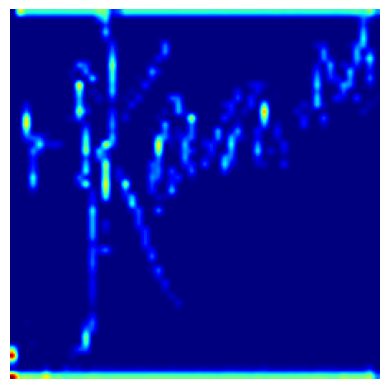

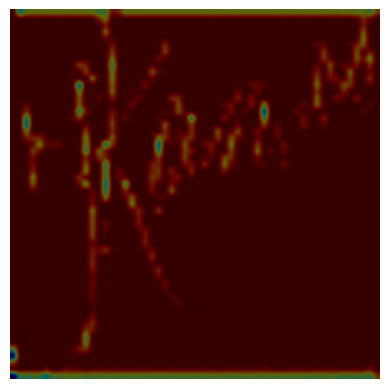

In [4]:
output = model(input_image)
predicted_class = output.argmax(dim=1).item()

# Generate Grad-CAM heatmap
heatmap = grad_cam.generate_cam(input_image, predicted_class)

# Display the heatmap
plt.imshow(heatmap, cmap='jet')
plt.axis('off')
plt.show()

# Superimpose the heatmap on the original image
heatmap = cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET)
input_image_np = input_image.squeeze().permute(1, 2, 0).cpu().numpy()

superimposed_img = heatmap * 0.4 + input_image_np
plt.imshow(superimposed_img / 255.0)
plt.axis('off')
plt.show()

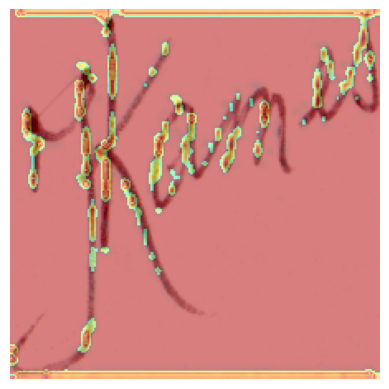

In [5]:
# Superimpose the heatmap on the original image, with better color retention
heatmap = cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET)

# Convert the input image to a format suitable for overlay
input_image_np = input_image.squeeze().permute(1, 2, 0).cpu().numpy()

# Check if the input image is grayscale (single channel)
if input_image_np.shape[-1] == 1:
    input_image_np = cv2.cvtColor(input_image_np, cv2.COLOR_GRAY2RGB)  # Convert to 3-channel RGB

# Normalize the original image if needed (adjust based on your data range)
input_image_np = input_image_np - input_image_np.min()
input_image_np = input_image_np / input_image_np.max()

# Blend heatmap and original image (alpha controls how much of each to show)
alpha = 0.5  # Adjust alpha to control blending
superimposed_img = cv2.addWeighted(heatmap, alpha, np.uint8(255 * input_image_np), 1 - alpha, 0)

# Display the superimposed image
plt.imshow(superimposed_img)
plt.axis('off')
plt.show()
